# Synthetic HSI generation — step by step

A walkthrough of `src/data_generation/`, one pipeline stage at a time, with the intermediate
arrays plotted at each step. Nothing here writes files.

The seven stages:

| stage | what happens | module |
|---|---|---|
| 0 | measured spectra resampled onto the wavelength grid | `spectral_library` |
| 1 | geometry rasterised to a **material index** per pixel | `pipeline`, `geometry` |
| 2a | blend pristine ↔ irradiated, one weight per scene | `pipeline` |
| 2b | spectral noise, one draw **per material** | `pipeline` |
| 2c | paint: extrude the mask into a cube | `pipeline` |
| 3a | per-band Gaussian blur, σ grows with λ | `pipeline` |
| 3b | sensor noise, independent per pixel and band | `pipeline` |

Notes:
1. The irradiation blend is not part of the noise modeling, it is part of building the spectrum.
2. There are **two noise terms, and the blur between them**.
   The first is shared across every pixel of a material; the second is
   independent per pixel. Swap the order and the statistics change.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm, LinearSegmentedColormap

from src.data_generation import SimConfig, SpectralLibrary, ID_TO_NAME, N_CLASSES
from src.data_generation.pipeline import (generate_sample, generate_batch, satellite_scene,
                                          shapes_scene, patches_scene, blur_cube, sensor_noise)
from src.data_generation.geometry import rasterize

ROOT = os.path.abspath("..")            # project root, for assets/materials

S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"                         # line colours: blue, orange, green
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8a8f", "#e4e4e2"  # text, ticks/labels, faint lines, grid
DIV = LinearSegmentedColormap.from_list("div", [S1, "#f2f2f0", S2])  # blue-white-orange, for signed values
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
})

def bare(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

## Configuration

Defaults: 36 bands over 350–1000 nm, sensor noise σ = 0.02.

`fingerprint()` is a hash of the whole config. Stamp it into anything you keep for references.

In [18]:
cfg = SimConfig()
# cfg = SimConfig(lambda_min_nm=400, lambda_max_nm=1000)

print("wavelength grid :", cfg.n_bands, "bands,",
      f"{cfg.lambda_min_nm:.0f}-{cfg.lambda_max_nm:.0f} nm,",
      f"step {cfg.wavelengths_nm[1]-cfg.wavelengths_nm[0]:.6f} nm")
print("psf sigma       :", f"{cfg.psf_sigma_px[0]:.3f} -> {cfg.psf_sigma_px[-1]:.3f} px")
print("sensor noise    :", cfg.sensor_noise_std)
print("image size      :", cfg.image_size, "x", cfg.image_size)
print("scene mix       :", dict(zip(["satellite","shapes","patches"], cfg.scene_probs.round(2))))
print("classes         :", N_CLASSES, "(0 = background)")
print("fingerprint     :", cfg.fingerprint())

wavelength grid : 36 bands, 350-1000 nm, step 18.571429 nm
psf sigma       : 0.583 -> 1.667 px
sensor noise    : 0.02
image size      : 15 x 15
scene mix       : {'satellite': np.float64(0.3), 'shapes': np.float64(0.3), 'patches': np.float64(0.4)}
classes         : 47 (0 = background)
fingerprint     : ec45d4018b39


---
## Stage 0 — the spectral library

46 materials, each with a pristine trace and (for 35 of them) an
electron-irradiated one, resampled onto the grid.

The blend is
$$s = (1-w)\,s_\text{pristine} + w\,s_\text{irradiated}, \qquad w \in [0,1]$$
with **one $w$ per scene** — so every part of the spacecraft is assumed to have
aged by exactly the same amount.

In [ ]:
# initialize lib

lib = SpectralLibrary(cfg, root=ROOT)
L = cfg.wavelengths_nm
print(f"{len(lib.materials)} materials, {sum(m.irradiated is not None for m in lib.materials.values())} with an irradiated trace")

"""
TODO: couple of comments regarding lib init logs. detection of artifacts looks ok, but it could be wrapped sliughtly differenly to make it more clear

1. Can we add a method to the library to make a reflectance plot of flagged materials? with names and stuff. we can make the picture size dynamic, something like panels of sqrt(n_flagged) x sqrt(n_flagged).
2. this method can fire in the end of creation by default (controlled by a flag in the config).
3. lib's creation message can be formatted a bit better, like we can add an additional line break before the explanation for severe and marginals.
4. also, it is difficult to figure out what to do with this information on severe and marginal artifactswhen it's returned, how can user act on this information, are there any methods for that? fine if we don't have these methods, it's just confusing
"""

46 materials, 35 with an irradiated trace


/var/folders/c7/h35llrbd2h76sn_0f75rjyz00000gq/T/ipykernel_46882/1477880460.py:3: SpectralLibraryWarning: 33 non-physical reflectance values across 17 spectra, on the 36-band 350-1000 nm grid.
  affected bands: [0, 1, 2, 10, 11, 12, 13, 14, 15, 16, 33, 34]  (lambda [350.0, 368.6, 387.1, 535.7, 554.3, 572.9, 591.4, 610.0, 628.6, 647.1, 962.9, 981.4] nm)
  19 severe (outside [-0.05, 1.05]), 14 marginal; 26 at a grid edge, 7 in the interior.
  AZW-LAII             irradiated  2 band(s), worst   +15.55 at band 0 (350.0 nm)
  AZJ-4020             irradiated  2 band(s), worst    -9.81 at band 0 (350.0 nm)
  AZ-400               irradiated  1 band(s), worst    -8.30 at band 0 (350.0 nm)
  AZ-93                pristine    1 band(s), worst    +7.21 at band 0 (350.0 nm)
  AZ-3700              irradiated  3 band(s), worst    -5.13 at band 0 (350.0 nm)
  AZ-2100              irradiated  1 band(s), worst    +5.13 at band 0 (350.0 nm)
  AZW-LAII             pristine    1 band(s), worst    +4.45 at b

"\nTODO: couple of comments regarding lib init logs. detection of artifacts looks ok, but it could be wrapped sliughtly differenly to make it more clear\n\n1. Can we add a method to the library to make a reflectance plot of flagged materials? with names and stuff. we can make the picture size dynamic, something like panels of sqrt(n_flagged) x sqrt(n_flagged).\n2. this method can fire in the end of creation by default (controlled by a flag in the config).\n3. lib's creation message can be formatted a bit better, like we can add an additional line break before the explanation for severe and marginals.\n"

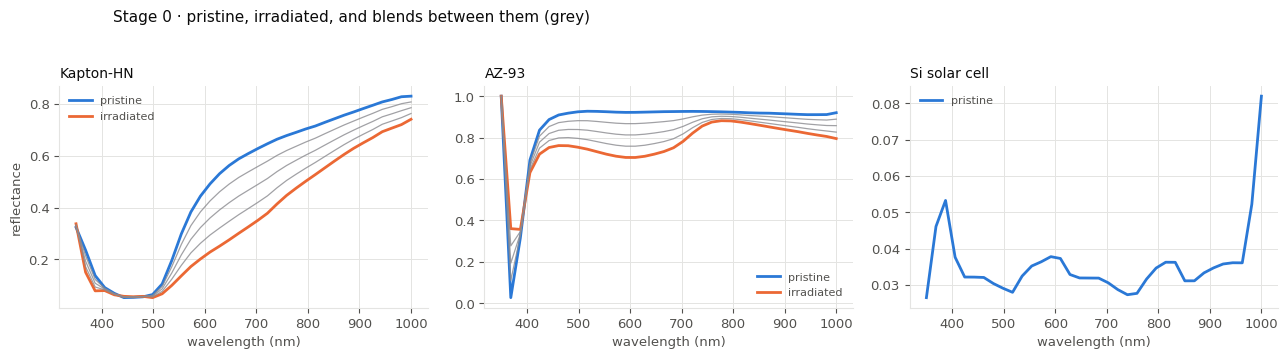

In [ ]:
# plot materials from the library
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, name in zip(axes, ["Kapton-HN", "AZ-93", "Si solar cell"]):
    m = lib.materials[name]
    ax.plot(L, m.pristine, color=S1, lw=2, label="pristine")
    if m.irradiated is not None:
        ax.plot(L, m.irradiated, color=S2, lw=2, label="irradiated")
        for w in (0.25, 0.5, 0.75):
            ax.plot(L, lib.blend(name, w), color=MUTED, lw=0.9, alpha=0.8)
    ax.set_title(name, fontsize=10, loc="left")
    ax.set_xlabel("wavelength (nm)"); ax.grid(True)
    ax.legend(frameon=False, fontsize=8, labelcolor=INK2)
axes[0].set_ylabel("reflectance")
fig.suptitle("Stage 0 · pristine, irradiated, and blends between them (grey)",
             y=1.04, fontsize=11, x=0.09, ha="left")
plt.tight_layout(); plt.show()

### Validating the library

Detection and handling are separate. The library **always** checks its resampled
spectra against [0, 1] over the target grid; `cfg.on_invalid` decides whether that
report is a warning, an exception, or silence, and `cfg.clip_reflectance` decides
what happens to the values. Nothing is fixed silently.

Band 0 sits exactly on 350 nm, where the seven AZ thermal-paint sheets *begin*.
DHR is a ratio, and at the UV edge both signal and reference approach zero, so the
quotient is noise: values from −9.8 to +15.6. The Kapton-family sheets show the same
thing at *their* first point (275 nm), far enough below the grid that interpolation
never sees it.

Note the distinction the report draws. **Severe** values at a grid edge carry no
information — clipping them fabricates a hard 1.0 where there is no measurement, so
trimming the grid is the honest fix. **Marginal** values just outside [0, 1] in
mid-band, like Aluminium 6061 at 1.01, are a calibration offset against the
reference standard; clipping those is reasonable.

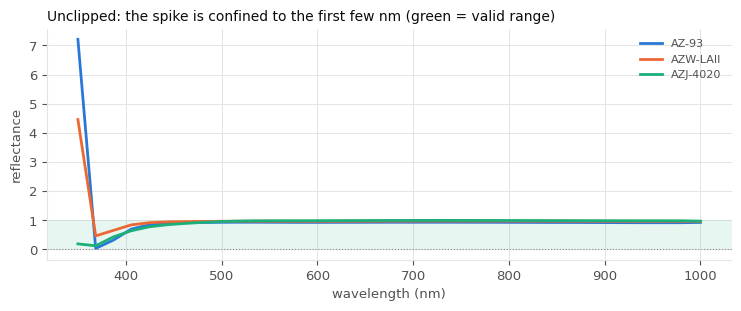

raw sheet values for AZ-93, first 6 points:
  350-355 nm pristine: 7.209, 3.676, 0.853, 0.680, 0.377, 0.333  -> settles ~0.28
  mid-band median: 0.924   (a white thermal paint, as expected)


In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for name, col in [("AZ-93", S1), ("AZW-LAII", S2), ("AZJ-4020", S3)]:
    ax.plot(L, lib.materials[name].pristine_raw, lw=2, color=col, label=name)   # unclipped
ax.axhspan(0, 1, color=S3, alpha=0.10, lw=0)
ax.axhline(0, color=MUTED, lw=0.8, ls=":")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("reflectance")
ax.set_title("Unclipped: the spike is confined to the first few nm (green = valid range)",
             fontsize=10, loc="left")
ax.legend(frameon=False, fontsize=8, labelcolor=INK2); ax.grid(True)
plt.tight_layout(); plt.show()

print("raw sheet values for AZ-93, first 6 points:")
print("  350-355 nm pristine: 7.209, 3.676, 0.853, 0.680, 0.377, 0.333  -> settles ~0.28")
print("  mid-band median: 0.924   (a white thermal paint, as expected)")

---
## Stage 1 — the scene mask
# TODO improve this descripion, previous version talked about weeds, and the purpose is supposed to brieflty explan to the user what's the purpose of this stage and how it works . 

This section creates a material mask for the scene using satellite_scene functions.

Three scene types, mixed 30 / 30 / 40. The satellite is a **minority** of the
training data — the manuscript does not mention this, and the largest single
share is the patch type, which carries no shape information at all.

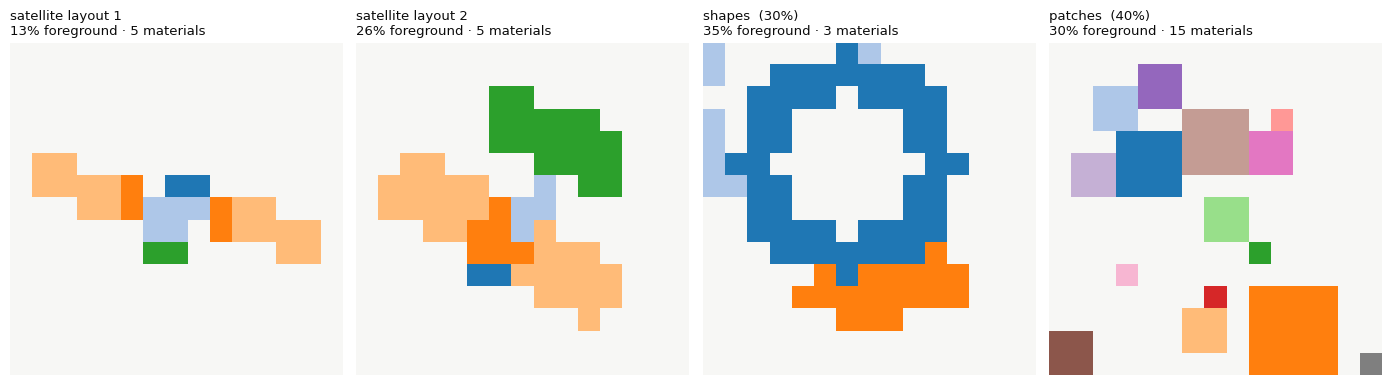

In [5]:
def show_mask(ax, mask, title):
    ids = [int(i) for i in np.unique(mask) if i]
    cols = ["#f7f7f5"] + [plt.cm.tab20(i % 20) for i in range(len(ids))]
    lut = np.zeros(int(mask.max()) + 1, int)
    for k, i in enumerate(ids): lut[i] = k + 1
    ax.imshow(lut[mask], cmap=ListedColormap(cols), vmin=0, vmax=len(ids),
              interpolation="nearest")
    bare(ax)
    ax.set_title(f"{title}\n{(mask!=0).mean():.0%} foreground · {len(ids)} materials",
                 fontsize=9.5, loc="left")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
show_mask(axes[0], satellite_scene(cfg, np.random.default_rng(3), variant=0)[0],
          "satellite layout 1")
show_mask(axes[1], satellite_scene(cfg, np.random.default_rng(3), variant=1)[0],
          "satellite layout 2")
show_mask(axes[2], shapes_scene(cfg, np.random.default_rng(3))[0], "shapes  (30%)")
show_mask(axes[3], patches_scene(cfg, np.random.default_rng(3))[0], "patches  (40%)")
plt.tight_layout(); plt.show()

# The original picks between the two satellite layouts with equal probability
# (`idx = np.random.randint(0,2)`), so half of all satellite scenes are layout 2:
# a wider bus, a 6-unit boom, and a 3.2-radius dish.  Alone it gives 26.4%
# foreground against layout 1's 13.5%.

### The satellite is grossly under-sampled — read this before trusting these masks

# TODO: same about this. explain the issue of undersampling with less details, just pooint the reader attention that this so they know what they work with.

At `image_size=15`, a 60° FOV gives focal length $f = 0.866 \times 15 = 13$ px.
At camera height 17 that makes the bus cylinder about **1.2 px across**, the
antenna 0.6 px, the connectors 0.23 px. Only the two solar panels (≈3 × 1.5 px
each, separated by ≈9 px) have real coverage.

The bus, antenna and connectors appear in the original's masks **only** because
it truncated projected vertices to `int32` and let `cv2.fillConvexPoly` fill
degenerate slivers generously. With an exact pixel-centre coverage test they
vanish and foreground drops from 13.5% to 5.6%.

So `rasterizer="cv2"` is the default — it is the only setting that reproduces the
mask statistics the trained models expect. But the honest reading is that the
"satellite" in the training set is largely a rasterisation artifact: a ~12 px
dumbbell of two panels with a couple of stray pixels between them.

Note the object always spans ~81% of the frame whatever `image_size` is, because
the FOV is fixed and the geometry just fits. To resolve it you raise
`image_size`, not move the camera — see `SimConfig.resolved()`.

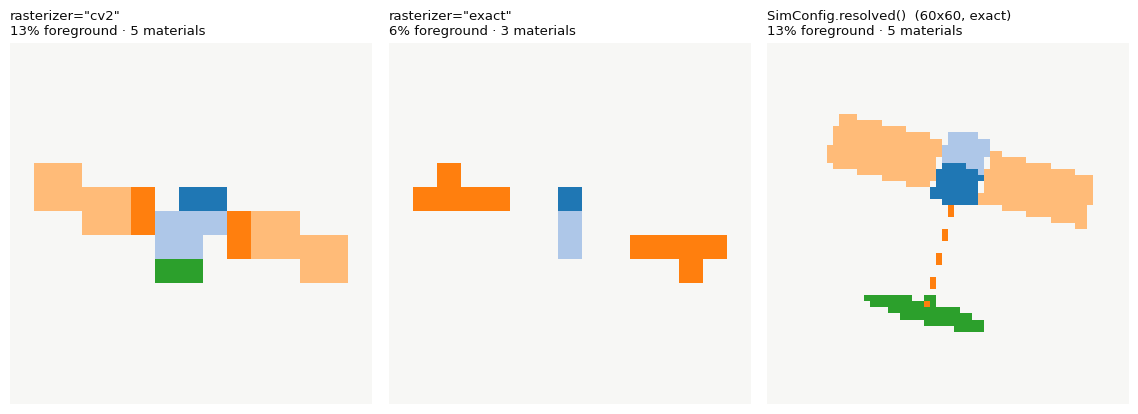

per-component coverage at 15x15, each rendered alone:
  Melinex             cv2   5 px   exact   2 px
  Kapton-MT           cv2   5 px   exact   2 px
  AZ-3700             cv2   6 px   exact   0 px
  Copper              cv2   4 px   exact   0 px
  Si solar cell       cv2  16 px   exact  10 px


In [6]:
from src.data_generation.pipeline import build_satellite

rng = np.random.default_rng(3)
comps, chosen = build_satellite(cfg, rng)
angles = np.array([float(rng.integers(45,135)), 0.0, float(rng.integers(-180,180))])

fig, axes = plt.subplots(1, 3, figsize=(11.5, 4))
for ax, mode in zip(axes[:2], ["cv2", "exact"]):
    c = cfg.with_(rasterizer=mode)
    m = rasterize(comps, c, angles)
    show_mask(ax, m, f'rasterizer="{mode}"')
show_mask(axes[2], satellite_scene(SimConfig.resolved(), np.random.default_rng(3))[0],
          "SimConfig.resolved()  (60x60, exact)")
plt.tight_layout(); plt.show()

print("per-component coverage at 15x15, each rendered alone:")
for i, (mesh, mid) in enumerate(comps):
    a = (rasterize([(mesh, mid)], cfg.with_(rasterizer="cv2"), angles) != 0).sum()
    b = (rasterize([(mesh, mid)], cfg.with_(rasterizer="exact"), angles) != 0).sum()
    print(f"  {ID_TO_NAME[mid]:18s}  cv2 {a:3d} px   exact {b:3d} px")

---
## Stages 2a–2c — painting the cube

# TODO: add a bit of intro to this section, and elsewhere if you see a chopped opening. e.g., I think here we can Say "Once the scene mask is created, we can generate the sample by painting the materials in the geometry with their spectral lib information.This is done in three steps: ...steps...

This is the step that surprises people: there is only **one** geometry render. # todo please check for other things that surprise people, it's something I was asking questions about, it's not necessarily needed a note on it.
Before blurring, every one of the 36 bands holds the *identical spatial pattern* —
only the constant value inside each region changes from band to band. The 36
slices carry zero extra spatial information over the single mask.

In [7]:
s = generate_sample(cfg, 3, lib, scene="satellite")
print(s.summary())

same = all(np.array_equal(s.cube_clean[0] != 0, s.cube_clean[j] != 0)
           for j in range(cfg.n_bands))
print(f"\nidentical spatial pattern in all {cfg.n_bands} clean bands: {same}")

Sample(seed=3, kind=satellite)
  grid            36 bands, 350.0-1000.0 nm (step 18.5714 nm)
  mask            (15, 15) uint8, ids [3, 6, 25, 32, 45]
  cube            (36, 15, 15) float64  <- model input
  foreground      24.4%   object span 12 px
  blend weight    w = 0.433 (shared by all materials)
  psf sigma       0.583 -> 1.667 px
  sensor noise    sigma = 0.02
  value range     clean [0.000, 1.000]  -> input [-0.066, 0.852]
  materials       3:Melinex, 6:Kapton-MT, 25:AZ-93, 32:CMX, 45:Copper

identical spatial pattern in all 36 clean bands: True


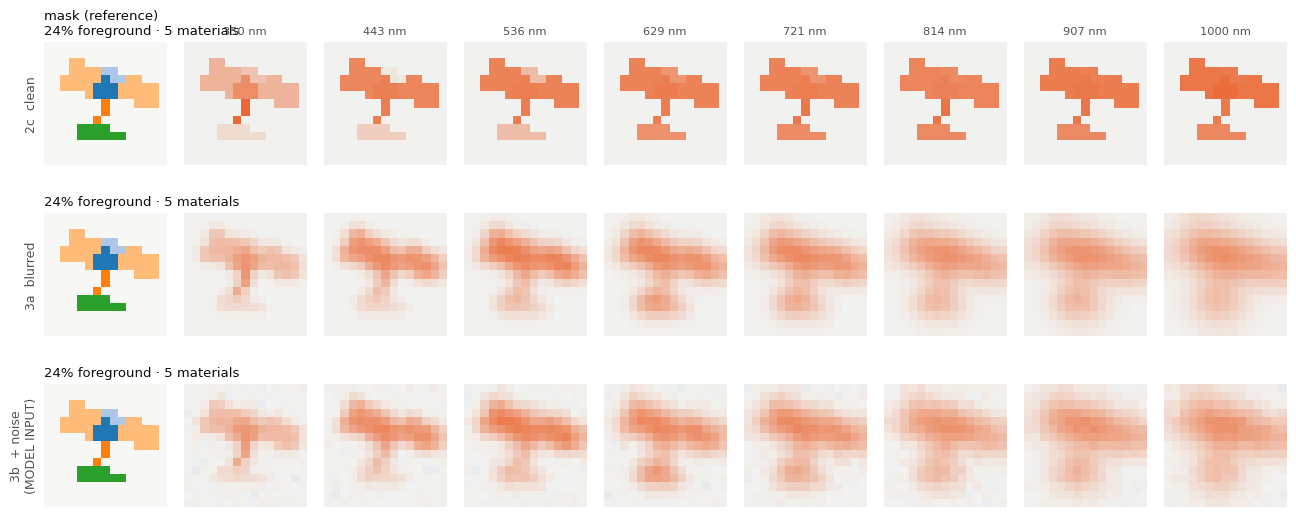

In [8]:
show = [0, 5, 10, 15, 20, 25, 30, 35]
vmax = max(abs(s.cube.min()), s.cube.max(), s.cube_clean.max())
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

fig, axes = plt.subplots(3, len(show)+1, figsize=(1.45*(len(show)+1), 5.4))
rows = [(s.cube_clean,   "2c  clean"),
        (s.cube_blurred, "3a  blurred"),
        (s.cube,         "3b  + noise\n(MODEL INPUT)")]
for r, (arr, lab) in enumerate(rows):
    show_mask(axes[r, 0], s.mask, "" if r else "mask (reference)")
    for c, j in enumerate(show):
        ax = axes[r, c+1]
        ax.imshow(arr[j], cmap=DIV, norm=norm, interpolation="nearest"); bare(ax)
        if r == 0: ax.set_title(f"{L[j]:.0f} nm", fontsize=8.2, color=INK2)
    axes[r, 0].set_ylabel(lab, fontsize=9, color=INK2)
plt.tight_layout(); plt.show()

# The panels look faint because Si solar cell reflects only ~0.03-0.08 while the
# bus materials reflect ~0.7-1.0.  Compare against the mask column: the geometry
# is all there, it is the *reflectance* that differs by an order of magnitude.
# That absolute-brightness difference is a real feature the model uses, which is
# also why these weights are not scale-invariant.

### The z-direction

Each pixel's spectrum. Solid lines are the clean blends (stage 2a); dashed are
after the shared per-material noise draw (stage 2b).

That noise draw is **one per material**, identical across every pixel of it — so
it does *not* average away when you pool pixels. This is why spatial pooling
saturates instead of driving accuracy to 1.

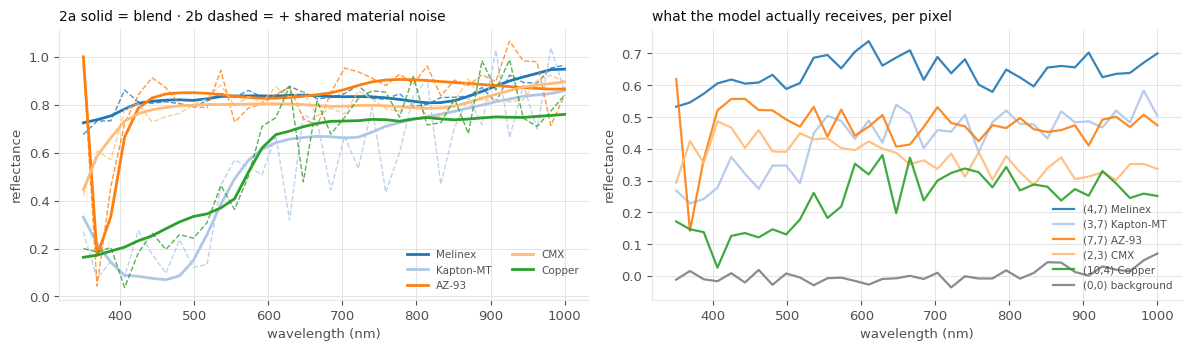

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
cols = [plt.cm.tab20(i % 20) for i in range(len(s.material_ids))]
for c, mid in zip(cols, s.material_ids):
    axes[0].plot(L, s.spectra_clean[mid], color=c, lw=2, label=ID_TO_NAME[mid])
    axes[0].plot(L, s.spectra_noisy[mid], color=c, lw=1, ls="--", alpha=0.8)
axes[0].set_title("2a solid = blend · 2b dashed = + shared material noise",
                  fontsize=10, loc="left")
axes[0].legend(frameon=False, fontsize=7.5, labelcolor=INK2, ncol=2)

for c, mid in zip(cols, s.material_ids):          # one pixel per material
    ys, xs = np.where(s.mask == mid)
    y, x = ys[0], xs[0]
    axes[1].plot(L, s.cube[:, y, x], lw=1.6, color=c, alpha=0.9,
                 label=f"({y},{x}) {ID_TO_NAME[mid]}")
axes[1].plot(L, s.cube[:, 0, 0], lw=1.6, color=MUTED, label="(0,0) background")
axes[1].set_title("what the model actually receives, per pixel", fontsize=10, loc="left")
axes[1].legend(frameon=False, fontsize=7.5, labelcolor=INK2)
for ax in axes:
    ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("reflectance"); ax.grid(True)
plt.tight_layout(); plt.show()

---
## Stage 3a — the PSF
# TODO: again, make a better opening, that's a common issue it seems, check other sections too.
$$\sigma_\text{px}(\lambda) = \frac{k\,\lambda/D}{p/f}$$

with $k = 0.25$, aperture $D = 3.6$ m, pixel pitch $p = 5\,\mu$m, focal length
$f = 120$ m — the diffraction limit of a 3.6 m telescope. σ runs 0.58 → 1.67 px.

**This is the only mechanism in the whole simulator that couples the spectral and
spatial axes.** Everything else treats them independently, so a network cannot
learn any spectral–spatial interaction beyond "redder is blurrier".

One inherited bug worth knowing: the original computed σ from a hard-coded
350–1000 nm ramp *regardless of the actual grid*, so its June `λ_max = 2000` runs
had blur that did not match their wavelengths. Here σ always follows the grid.

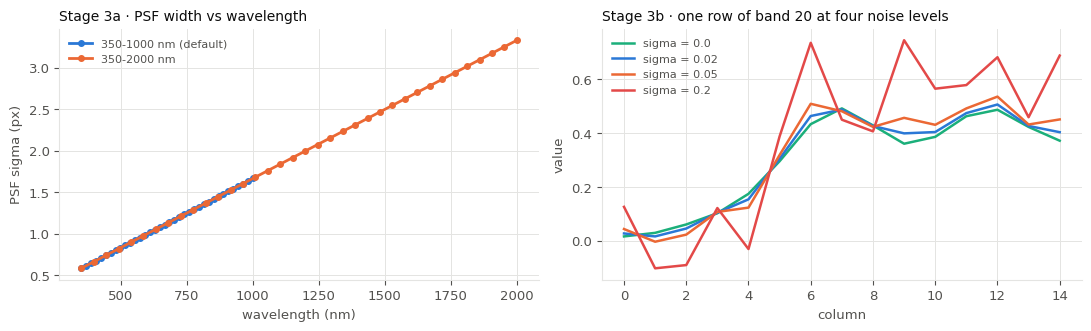

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(L, cfg.psf_sigma_px, "-o", color=S1, lw=2, ms=4, label="350-1000 nm (default)")
c2000 = cfg.with_(lambda_max_nm=2000)
axes[0].plot(c2000.wavelengths_nm, c2000.psf_sigma_px,
             "-o", color=S2, lw=2, ms=4, label="350-2000 nm")
axes[0].set_xlabel("wavelength (nm)"); axes[0].set_ylabel("PSF sigma (px)")
axes[0].set_title("Stage 3a · PSF width vs wavelength", fontsize=10, loc="left")
axes[0].legend(frameon=False, fontsize=8, labelcolor=INK2); axes[0].grid(True)

for sd, col in [(0.0, S3), (0.02, S1), (0.05, S2), (0.20, "#e34948")]:
    prof = sensor_noise(s.cube_blurred, cfg.with_(sensor_noise_std=sd),
                        np.random.default_rng(0))[20, 7, :]
    axes[1].plot(prof, lw=1.8, color=col, label=f"sigma = {sd}")
axes[1].set_xlabel("column"); axes[1].set_ylabel("value")
axes[1].set_title("Stage 3b · one row of band 20 at four noise levels", fontsize=10, loc="left")
axes[1].legend(frameon=False, fontsize=8, labelcolor=INK2); axes[1].grid(True)
plt.tight_layout(); plt.show()

Noise is what destroys **material** identification; shape survives far more of
it. Worth remembering when writing claims: "we recover shape robustly" is much
better supported than "we recover materials".

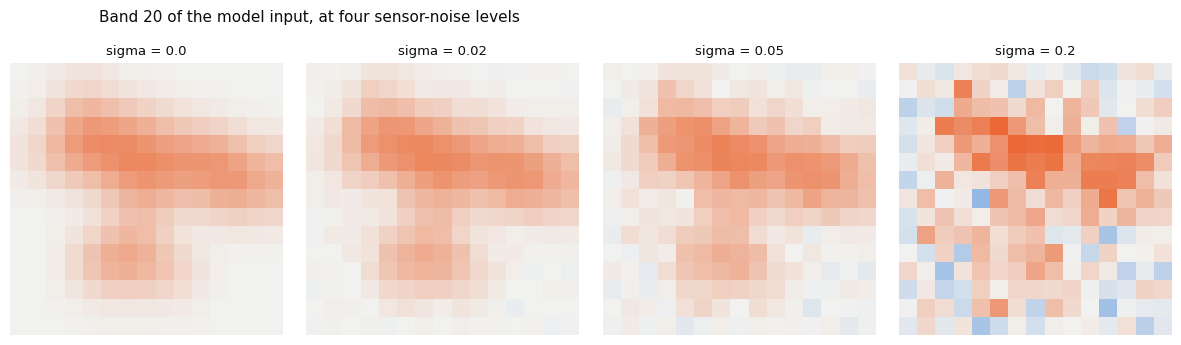

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, sd in zip(axes, [0.0, 0.02, 0.05, 0.20]):
    c = sensor_noise(s.cube_blurred, cfg.with_(sensor_noise_std=sd), np.random.default_rng(1))
    ax.imshow(c[20], cmap=DIV, norm=TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax),
              interpolation="nearest")
    bare(ax); ax.set_title(f"sigma = {sd}", fontsize=9.5)
fig.suptitle("Band 20 of the model input, at four sensor-noise levels",
             y=1.03, fontsize=11, x=0.09, ha="left")
plt.tight_layout(); plt.show()

---
## End result: scene statistics

For reference, the original `moduler_gen.py` gave about: satellite 20% foreground /
4.9 materials; shapes 21% / 2.0; patches 34% / 11.9. The defaults differ on purpose
for shapes (real triangles, ≈23%) and patches (unique labels, ≈13.5 materials).

In [12]:
for scene in ["satellite", "shapes", "patches"]:
    B = generate_batch(cfg, lib, 150, seed0=0, scene=scene)
    B = [b for b in B if b.foreground_fraction > 0]
    print(f"{scene:10s} fg {np.mean([b.foreground_fraction for b in B]):5.1%}"
          f"   span {np.mean([b.object_span_px for b in B]):4.1f} px"
          f"   materials/scene {np.mean([len(b.material_ids) for b in B]):4.1f}")

satellite  fg 20.8%   span 12.4 px   materials/scene  4.9
shapes     fg 23.1%   span 11.6 px   materials/scene  2.1
patches    fg 33.9%   span 14.8 px   materials/scene 13.6


### Optional — feed the paper's trained checkpoint

If you have `resluts_n_model/yes_id/model_nozoom_with_shapes.pt`, this is the
end-to-end validation: a faithful pipeline should reproduce the paper's Table 1.

Expected ≈ 0.80 material / 0.985 shape at σ = 0.02. Paper reports 0.764 / 0.992
(its noise sat between σ = 0.02 and 0.03).

In [13]:
CKPT = "/Users/ppopov1/_remote_data/satellite_project/resluts_n_model/yes_id/model_nozoom_with_shapes.pt"   # <-- edit

if os.path.exists(CKPT):
    import torch
    model = torch.jit.load(CKPT, map_location="cpu").eval()
    ma, sa = [], []
    for i in range(120):
        smp = generate_sample(cfg, 5000 + i, lib, scene="satellite")
        fg = smp.mask != 0
        if not fg.sum(): continue
        with torch.no_grad():
            p = model(torch.from_numpy(smp.cube).float()[None]).argmax(1)[0].numpy()
        ma.append((p[fg] == smp.mask[fg]).mean()); sa.append(((p != 0) == fg).mean())
    print(f"material accuracy {np.mean(ma):.3f}   shape accuracy {np.mean(sa):.3f}   (n={len(ma)})")
    print("paper Table 1:    0.764                0.992")
else:
    print("checkpoint not found — set CKPT above to run this cell")

checkpoint not found — set CKPT above to run this cell


---
## Defects of the original, fixed here

| the original | here |
|---|---|
| fed detector artifacts (−9.8 … +15.6) into band 0 | reported by `on_invalid`, clipped by `clip_reflectance` |
| zero-padded past the last measured λ, fingerprinting materials by where their data stops | reported by `on_unmeasured`, held by `extrapolate_red="hold"` |
| skipped faces touching the frame edge instead of clipping them | clipped |
| built "triangles" from 2 points, so every one was a line | real triangles (#TODO what was the issue with it?)|

Not reproduced, because it was a data-corruption bug rather than a modelling
choice: the original saved mask, cube and clean cube as **three separate `.npy` files**
into a 1000-slot ring buffer being overwritten at ~4800 writes/s. A DataLoader could
read the cube from one scene and the mask from another; shapes always matched, so
`YesIDMaskDataset`'s check passed and the mismatch entered training as silent
label noise. If you add saving, write everything into one `.npz`, or write to a temp
name and `os.replace`.

## Still missing, physically

- **No illumination at all.** No solar spectrum, no atmospheric transmission, no
  instrument response. The output is dimensionless reflectance, which is why a
  real radiance cube cannot be fed to these models without dividing those out.
- **The additive Gaussian is not atmosphere.** Atmosphere is multiplicative and
  spectrally structured — Rayleigh ∼ λ⁻⁴, the O₂ A-band at 760 nm, water vapour
  at 720 and 820 nm. Adding a transmission term is the largest fidelity gap.
- **No geometry in the radiometry.** DHR is used as if it were a BRDF value at
  the observed angle, so orientation never affects brightness.
- **λ stops at 1000 (or 2000) nm** while the library reaches ~2500 nm. The
  2000–2500 nm window roughly doubles 46-way material separability — the single
  highest-value change available, and it is one number in the config.